# Task 2 — Segmenting eggs with image processing

Here I build a traditional image-processing method to find eggs, without training a new model. I use the Task 1 masks as reference labels and compare each experiment against them.

The notebook first tries simple thresholding and GrabCut. Those methods often include bowls, trays, or cloth along with the egg. Later experiments search for an egg-shaped outline and refine it with GrabCut. The experiments and their results are recorded below.

**To run this in Kaggle:** add the image dataset and the Task 1 results folder as inputs. The results folder should contain `combined_masks/`. No GPU is needed. The final cells save masks, metrics, the chosen settings, and a zip file under `/kaggle/working/task2_results`.

The split is made by source photo and near-duplicate image checks, so copies of the same scene are kept together. The notebook uses the development split to choose settings and reports results on the evaluation split at the end.


In [19]:
import os, re, json, math, time, shutil, random, warnings, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)

# ---- paths (environment variables allow running outside Kaggle) ----
INPUT_DIR = Path(os.environ.get("EGG_IMG_DIR", "/kaggle/input/datasets/dewangchoudhary/eggsss/Dataset"))
MASK_DIR_OVERRIDE = os.environ.get("EGG_MASK_DIR", "")   # leave empty to auto-discover Task 1 'combined_masks'
OUT_DIR = Path(os.environ.get("EGG_OUT_DIR", "/kaggle/working/task2_results"))
shutil.rmtree(OUT_DIR, ignore_errors=True)
for sub in ["pred_masks/dev", "pred_masks/eval", "figures"]:
    (OUT_DIR / sub).mkdir(parents=True, exist_ok=True)

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
EVAL_FRACTION = 0.2          # 4:1 dev:eval
HASH_HAMMING_THR = 5         # near-duplicate threshold on 64-bit dHash
MIN_GAIN = 0.002             # a trial is kept only if dev mIoU improves by more than this
print("OpenCV:", cv2.__version__)

OpenCV: 4.14.0


## 1. Load the images and reference masks

Each image is paired with its Task 1 mask using the filename. Task 1 produced an empty mask for one image; that image is listed and left out of the metric calculations.

In [20]:
# ---- locate Task 1 masks ----
# Expected on Kaggle: /kaggle/input/.../task1_results/task1_results/combined_masks/<split>/egg/<stem>_mask.png
def has_masks(d):
    return d.is_dir() and any(True for _ in d.rglob("*_mask.png"))

def find_mask_dir():
    if MASK_DIR_OVERRIDE:
        return Path(MASK_DIR_OVERRIDE)
    roots = [Path("/kaggle/input"), Path("/kaggle/working")]
    for root in roots:
        if not root.exists():
            continue
        for d in sorted(root.rglob("combined_masks")):
            if has_masks(d):
                return d
    # fall back: unzip a task1_results.zip if one was attached
    for root in roots:
        if root.exists():
            zips = list(root.rglob("task1_results.zip"))
            if zips:
                dest = Path("/kaggle/working/task1_extracted")
                with zipfile.ZipFile(zips[0]) as z:
                    z.extractall(dest)
                for d in sorted(dest.rglob("combined_masks")):
                    if has_masks(d):
                        return d
    raise FileNotFoundError("Could not find Task 1 'combined_masks' with *_mask.png files. "
                            "Attach the task1_results dataset via Add Input, or set MASK_DIR_OVERRIDE.")

MASK_DIR = find_mask_dir()
print("Task 1 masks:", MASK_DIR)

mask_lookup = {p.name[:-len("_mask.png")]: p for p in MASK_DIR.rglob("*_mask.png")}
image_paths = sorted(p for p in INPUT_DIR.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)
print("Images:", len(image_paths), "| masks:", len(mask_lookup))

items, skipped = [], []
for p in image_paths:
    if p.stem not in mask_lookup:
        skipped.append((p.name, "no mask file")); continue
    img = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
    gt = cv2.imread(str(mask_lookup[p.stem]), cv2.IMREAD_GRAYSCALE)
    if gt.shape != img.shape[:2]:
        gt = cv2.resize(gt, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)
    gt = gt > 127
    if gt.sum() == 0:
        skipped.append((p.name, "empty Task 1 mask")); continue
    items.append({"name": p.name, "stem": p.stem, "img": img, "gt": gt})

print("Usable image/mask pairs:", len(items))
print("Skipped:", len(skipped))
for s in skipped: print("  ", s)

Task 1 masks: /kaggle/input/datasets/dewangchoudhary/task1-results/task1_results/combined_masks
Images: 110 | masks: 110
Usable image/mask pairs: 109
Skipped: 1
   ('not_damaged_117_jpg.rf.d25ded9e7408f9b89b3cfb3de581f6a6.jpg', 'empty Task 1 mask')


## 2. Make development and evaluation splits

A random file-by-file split could put two copies of the same photo on both sides and make the evaluation score look better than it should. To reduce that risk, this cell groups images from the same source photo and also checks for near-identical images with a perceptual hash. Each group goes entirely into development or evaluation.

The target is about four development images for every evaluation image. The original Roboflow train, validation, and test folders are not used for this split.

In [21]:
BASE_RE = re.compile(r"^(.*?)_jpg\.rf\.", re.I)
def base_id(stem):
    m = BASE_RE.match(stem)
    return m.group(1) if m else stem

def dhash(img, size=8):
    g = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    g = cv2.resize(g, (size + 1, size), interpolation=cv2.INTER_AREA)
    return (g[:, 1:] > g[:, :-1]).flatten()

N = len(items)
hashes = np.stack([dhash(it["img"]) for it in items])
parent = list(range(N))
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x
def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb: parent[rb] = ra

# step 1: same source photo
first_with_id = {}
for i, it in enumerate(items):
    b = base_id(it["stem"]); it["base_id"] = b
    if b in first_with_id: union(first_with_id[b], i)
    else: first_with_id[b] = i
groups_after_ids = len({find(i) for i in range(N)})

# step 2: near-duplicate images
ham = (hashes[:, None, :] != hashes[None, :, :]).sum(-1)
n_merges = 0
for i in range(N):
    for j in range(i + 1, N):
        if ham[i, j] <= HASH_HAMMING_THR and find(i) != find(j):
            union(i, j); n_merges += 1

groups = {}
for i in range(N):
    groups.setdefault(find(i), []).append(i)
print(f"{N} images -> {groups_after_ids} source-photo groups -> {len(groups)} groups after near-duplicate merging ({n_merges} merges)")
sizes = sorted((len(v) for v in groups.values()), reverse=True)
print("Largest group sizes:", sizes[:8])

# assign whole groups to eval until ~20% of images
rng = np.random.RandomState(SEED)
order = list(groups.keys()); rng.shuffle(order)
target_eval = int(round(EVAL_FRACTION * N))
eval_idx, dev_idx = [], []
for g in order:
    members = groups[g]
    if len(eval_idx) + len(members) <= target_eval: eval_idx += members
    else: dev_idx += members

for i in dev_idx: items[i]["split"] = "dev"
for i in eval_idx: items[i]["split"] = "eval"
dev_items = [items[i] for i in sorted(dev_idx)]
eval_items = [items[i] for i in sorted(eval_idx)]

# audits
dev_groups = {find(i) for i in dev_idx}; eval_groups = {find(i) for i in eval_idx}
assert not (dev_groups & eval_groups), "group leaked across splits!"
assert not ({it["base_id"] for it in dev_items} & {it["base_id"] for it in eval_items}), "source photo leaked!"
min_cross = ham[np.ix_(dev_idx, eval_idx)].min() if len(eval_idx) and len(dev_idx) else None
print(f"dev = {len(dev_items)}, eval = {len(eval_items)} (ratio {len(dev_items)/max(len(eval_items),1):.2f}:1)")
print("Min dHash Hamming distance between any dev and eval image:", min_cross, f"(threshold {HASH_HAMMING_THR})")

split_df = pd.DataFrame([{"image": it["name"], "base_id": it["base_id"], "split": it["split"]} for it in items])
split_df.to_csv(OUT_DIR / "split.csv", index=False)

109 images -> 109 source-photo groups -> 108 groups after near-duplicate merging (1 merges)
Largest group sizes: [2, 1, 1, 1, 1, 1, 1, 1]
dev = 87, eval = 22 (ratio 3.95:1)
Min dHash Hamming distance between any dev and eval image: 13 (threshold 5)


## 3. How the masks are scored

Task 1 masks are used as reference labels. For each image, the notebook compares the predicted foreground mask with that reference and reports IoU, Dice, precision, and recall. Mean development IoU is the main score used to decide whether an experiment is worth keeping.

In [22]:
def seg_metrics(pred, gt):
    pred = pred.astype(bool); gt = gt.astype(bool)
    tp = np.logical_and(pred, gt).sum(); fp = np.logical_and(pred, ~gt).sum(); fn = np.logical_and(~pred, gt).sum()
    eps = 1e-9
    return {"iou": tp / (tp + fp + fn + eps),
            "dice": 2 * tp / (2 * tp + fp + fn + eps),
            "precision": tp / (tp + fp + eps),
            "recall": tp / (tp + fn + eps)}

## 4. The image-processing methods

Images are reduced in size while the algorithm runs, then the finished mask is returned to the original image size.

The first methods try to separate eggs by pixel appearance: Otsu brightness thresholding, a white-pixel rule in HSV colour, colour difference from the image border, and GrabCut started from a box near the centre. There is also a candidate method that scores blobs by shape, colour contrast, and whether they touch the image edge.

The later method searches over possible ellipse outlines. It scores the colour change around each outline, the texture inside it, and its size. GrabCut can then tidy the boundary within a limited area around the ellipse. The experiment section below shows why this later approach was chosen.

In [23]:
BASE_CFG = dict(
    method="otsu", proc_size=320, blur=5, open_k=7, min_area=0.008, max_area=0.8, max_eggs=3,
    hsv_s=60, hsv_v=140, canny_lo=40, canny_hi=120, canny_close=5, rect_margin=0.12,
    gens=("otsu", "hsv", "border"), score_thr=0.6,
    w_ell=0.35, w_sol=0.15, w_ratio=0.15, w_con=0.25, w_white=0.10, w_border=0.6,
    refine=None, gc_iters=4, gc_core=0.35, gc_band=0.25, ellipse_blend=None,
    # ---- phase 2: ellipse search (defaults = the naive first version) ----
    search_size=160, center_step=8, a_fracs=(0.07, 0.10, 0.14, 0.19, 0.25, 0.32, 0.40),
    ratios=(0.6, 0.75, 0.9), theta_step=30, d=3.0, w_mean=0.5, pct=25, cap=35.0,
    dark_w=0.7, w_int=0.0, w_size=0.0, n_refine=8,
    extra_ratio=0.7, extra_area=0.0, extra_dlab=1e9, extra_overlap=1.0,
    ell_refine=None, eg_size=160, eg_core=0.55, eg_out=1.35, eg_iters=3, eg_guard=0.6, eg_union=0.0, eg_clean=1,
)

def odd(k):
    k = int(max(1, round(k)))
    return k if k % 2 == 1 else k + 1

def ell_kernel(k):
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (odd(k), odd(k)))

def to_work(img, size):
    h, w = img.shape[:2]
    s = min(1.0, size / max(h, w))
    if s < 1.0:
        return cv2.resize(img, (int(round(w * s)), int(round(h * s))), interpolation=cv2.INTER_AREA)
    return img.copy()

def fill_holes(mask):
    m = mask.astype(np.uint8)
    cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    out = np.zeros_like(m)
    cv2.drawContours(out, cnts, -1, 1, thickness=-1)
    return out.astype(bool)

def components(mask, min_area_px):
    n, lab, stats, _ = cv2.connectedComponentsWithStats(mask.astype(np.uint8), connectivity=8)
    return [lab == i for i in range(1, n) if stats[i, cv2.CC_STAT_AREA] >= min_area_px]

def postprocess(mask, cfg):
    h, w = mask.shape
    k = ell_kernel(cfg["open_k"])
    m = cv2.morphologyEx(mask.astype(np.uint8), cv2.MORPH_OPEN, k)
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, k)
    m = fill_holes(m)
    comps = sorted(components(m, cfg["min_area"] * h * w), key=lambda c: -c.sum())[: cfg["max_eggs"]]
    out = np.zeros((h, w), bool)
    for c in comps: out |= c
    return out

# ---------------- foreground generators ----------------
def gen_otsu(iw, cfg):
    g = cv2.GaussianBlur(cv2.cvtColor(iw, cv2.COLOR_RGB2GRAY), (odd(cfg["blur"]),) * 2, 0)
    t, _ = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    b = g > t
    return [b, ~b]

def gen_hsv(iw, cfg):
    hsv = cv2.cvtColor(iw, cv2.COLOR_RGB2HSV)
    s, v = hsv[..., 1], hsv[..., 2]
    return [(s < cfg["hsv_s"]) & (v > cfg["hsv_v"]),
            (s < cfg["hsv_s"] * 0.7) & (v > cfg["hsv_v"] * 0.7)]

def gen_border(iw, cfg, frac=0.08):
    lab = cv2.cvtColor(iw, cv2.COLOR_RGB2LAB).astype(np.float32)
    h, w = lab.shape[:2]; b = max(2, int(frac * min(h, w)))
    ring = np.zeros((h, w), bool)
    ring[:b] = True; ring[-b:] = True; ring[:, :b] = True; ring[:, -b:] = True
    bg = np.median(lab[ring], axis=0)
    d = np.linalg.norm(lab - bg, axis=2)
    d8 = np.clip(d / max(d.max(), 1e-6) * 255, 0, 255).astype(np.uint8)
    d8 = cv2.GaussianBlur(d8, (odd(cfg["blur"]),) * 2, 0)
    t, _ = cv2.threshold(d8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return [d8 > t]

def gen_canny(iw, cfg):
    g = cv2.GaussianBlur(cv2.cvtColor(iw, cv2.COLOR_RGB2GRAY), (5, 5), 0)
    e = cv2.Canny(g, cfg["canny_lo"], cfg["canny_hi"])
    e = cv2.morphologyEx(e, cv2.MORPH_CLOSE, ell_kernel(cfg["canny_close"]))
    return [e == 0]          # regions enclosed by edges

GENS = {"otsu": gen_otsu, "hsv": gen_hsv, "border": gen_border, "canny": gen_canny}

def grabcut_rect(iw, cfg):
    h, w = iw.shape[:2]
    mx, my = int(cfg["rect_margin"] * w), int(cfg["rect_margin"] * h)
    mask = np.zeros((h, w), np.uint8)
    bgd = np.zeros((1, 65)); fgd = np.zeros((1, 65))
    cv2.setRNGSeed(SEED)     # GrabCut's GMM init is random; fix it so trials are reproducible
    cv2.grabCut(cv2.cvtColor(iw, cv2.COLOR_RGB2BGR), mask, (mx, my, w - 2 * mx, h - 2 * my),
                bgd, fgd, cfg["gc_iters"], cv2.GC_INIT_WITH_RECT)
    return (mask == cv2.GC_FGD) | (mask == cv2.GC_PR_FGD)

# ---------------- candidate generation + egg-likeness scoring ----------------
def candidate_components(iw, cfg):
    h, w = iw.shape[:2]
    k = ell_kernel(cfg["open_k"])
    out = []
    for g in cfg["gens"]:
        for b in GENS[g](iw, cfg):
            m = cv2.morphologyEx(b.astype(np.uint8), cv2.MORPH_OPEN, k)
            m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, k)
            for c in components(m, cfg["min_area"] * h * w):
                c = fill_holes(c)
                if c.sum() / (h * w) <= cfg["max_area"]:
                    out.append(c)
    return out

def score_component(comp, lab, cfg):
    h, w = comp.shape
    m = comp.astype(np.uint8)
    cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    if not cnts: return None
    c = max(cnts, key=cv2.contourArea)
    if len(c) < 5: return None
    area = cv2.contourArea(c)
    if area < 1: return None
    hull = cv2.contourArea(cv2.convexHull(c))
    solidity = area / max(hull, 1e-6)
    try:
        ell = cv2.fitEllipse(c)
    except cv2.error:
        return None
    em = np.zeros((h, w), np.uint8); cv2.ellipse(em, ell, 1, -1); em = em.astype(bool)
    ell_iou = (em & comp).sum() / max((em | comp).sum(), 1)
    ax = sorted(ell[1]); ratio = ax[1] / max(ax[0], 1e-6)
    ratio_score = math.exp(-((math.log(max(ratio, 1.0)) - math.log(1.3)) ** 2) / (2 * 0.35 ** 2))
    peri = cv2.arcLength(c, True)
    touch = comp[0, :].sum() + comp[-1, :].sum() + comp[:, 0].sum() + comp[:, -1].sum()
    border_frac = min(1.0, touch / max(peri, 1.0))
    r = math.sqrt(area / math.pi)
    ring = (cv2.dilate(m, ell_kernel(max(5, 0.3 * r))) > 0) & ~comp
    contrast = np.linalg.norm(lab[comp].mean(0) - lab[ring].mean(0)) if ring.sum() >= 10 else 0.0
    contrast_s = min(1.0, contrast / 40.0)
    chroma = np.sqrt(((lab[comp][:, 1:] - 128.0) ** 2).sum(1)).mean()
    white_s = float(np.clip(1 - chroma / 40.0, 0, 1))
    return (cfg["w_ell"] * ell_iou + cfg["w_sol"] * solidity + cfg["w_ratio"] * ratio_score
            + cfg["w_con"] * contrast_s + cfg["w_white"] * white_s - cfg["w_border"] * border_frac)

def select_eggs(cands, lab, cfg):
    scored = []
    for c in cands:
        s = score_component(c, lab, cfg)
        if s is not None: scored.append((s, c))
    scored.sort(key=lambda t: -t[0])
    sel = []
    for s, c in scored:
        if len(sel) >= cfg["max_eggs"]: break
        overlap = any((c & k).sum() / max(min(c.sum(), k.sum()), 1) > 0.3 for _, k in sel)
        if overlap: continue
        if not sel or s >= cfg["score_thr"]:
            sel.append((s, c))
    return sel

# ---------------- refinement ----------------
def grabcut_refine(iw, union, cfg):
    h, w = union.shape
    area = union.sum()
    if area < 50: return union
    r = math.sqrt(area / math.pi)
    u8 = union.astype(np.uint8)
    sure = cv2.erode(u8, ell_kernel(cfg["gc_core"] * r * 2)) > 0
    band = cv2.dilate(u8, ell_kernel(cfg["gc_band"] * r * 2)) > 0
    if sure.sum() < 20: sure = union
    mask = np.full((h, w), cv2.GC_BGD, np.uint8)
    mask[band] = cv2.GC_PR_BGD
    mask[union] = cv2.GC_PR_FGD
    mask[sure] = cv2.GC_FGD
    bgd = np.zeros((1, 65)); fgd = np.zeros((1, 65))
    cv2.setRNGSeed(SEED)
    try:
        cv2.grabCut(cv2.cvtColor(iw, cv2.COLOR_RGB2BGR), mask, None, bgd, fgd, cfg["gc_iters"], cv2.GC_INIT_WITH_MASK)
    except cv2.error:
        return union
    return (mask == cv2.GC_FGD) | (mask == cv2.GC_PR_FGD)

def ellipse_blend(mask, thr):
    out = np.zeros_like(mask)
    for c in components(mask, 20):
        used = c
        cnts, _ = cv2.findContours(c.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cc = max(cnts, key=cv2.contourArea)
        if len(cc) >= 5:
            try:
                em = np.zeros(c.shape, np.uint8); cv2.ellipse(em, cv2.fitEllipse(cc), 1, -1); em = em.astype(bool)
                if (em & c).sum() / max((em | c).sum(), 1) >= thr: used = em
            except cv2.error:
                pass
        out |= used
    return out

# ---------------- full pipeline ----------------
def segment(img, cfg):
    H, W = img.shape[:2]
    if cfg["method"] == "ellipse":
        return segment_ellipse(img, cfg)
    iw = to_work(img, cfg["proc_size"])
    m = cfg["method"]
    if m == "otsu":           raw = gen_otsu(iw, cfg)[0]
    elif m == "hsv":          raw = gen_hsv(iw, cfg)[0]
    elif m == "border":       raw = gen_border(iw, cfg)[0]
    elif m == "grabcut_rect": raw = grabcut_rect(iw, cfg)
    elif m == "candidates":
        lab = cv2.cvtColor(iw, cv2.COLOR_RGB2LAB).astype(np.float32)
        sel = select_eggs(candidate_components(iw, cfg), lab, cfg)
        raw = np.zeros(iw.shape[:2], bool)
        for _, c in sel: raw |= c
    else:
        raise ValueError(m)
    pp = postprocess(raw, cfg)
    if cfg.get("refine") == "grabcut" and pp.any():
        pp = postprocess(grabcut_refine(iw, pp, cfg), cfg)
    if cfg.get("ellipse_blend") and pp.any():
        pp = ellipse_blend(pp, cfg["ellipse_blend"])
    return cv2.resize(pp.astype(np.uint8) * 255, (W, H), interpolation=cv2.INTER_LINEAR) > 127

# =====================================================================
# PHASE 2: ellipse search ("find the egg-shaped outline"), then optional GrabCut inside it
# =====================================================================
def ellipse_pts(cx, cy, a, b, th, K=36):
    # points on N ellipses (N,K) and their outward unit normals
    t = np.linspace(0, 2 * np.pi, K, endpoint=False)[None, :]
    ct, st = np.cos(t), np.sin(t)
    c, s_ = np.cos(th)[:, None], np.sin(th)[:, None]
    ex, ey = a[:, None] * ct, b[:, None] * st
    x = cx[:, None] + c * ex - s_ * ey
    y = cy[:, None] + s_ * ex + c * ey
    nx0, ny0 = ct / a[:, None], st / b[:, None]
    nx, ny = c * nx0 - s_ * ny0, s_ * nx0 + c * ny0
    nn = np.sqrt(nx ** 2 + ny ** 2) + 1e-9
    return x, y, nx / nn, ny / nn

def draw_ellipse(shape, e):
    m = np.zeros(shape, np.uint8)
    cv2.ellipse(m, ((float(e[0]), float(e[1])), (float(2 * e[2]), float(2 * e[3])), float(np.rad2deg(e[4]))), 1, -1)
    return m.astype(bool)

def grad_mag(lab):
    g = np.zeros(lab.shape[:2], np.float32)
    for ch in range(3):
        gx = cv2.Sobel(lab[..., ch], cv2.CV_32F, 1, 0, ksize=3) / 8.0
        gy = cv2.Sobel(lab[..., ch], cv2.CV_32F, 0, 1, ksize=3) / 8.0
        g += gx ** 2 + gy ** 2
    return np.sqrt(g)

def sample(img2d, x, y):
    H, W = img2d.shape[:2]
    return img2d[np.clip(np.rint(y), 0, H - 1).astype(int), np.clip(np.rint(x), 0, W - 1).astype(int)]

def score_ellipses(lab, gm, cx, cy, a, b, th, P):
    # Egg-outline score = colour contrast across the boundary (inside vs outside, 36 points)
    #                     - penalty for texture inside the ellipse (eggs are smooth).
    H, W = lab.shape[:2]; d = P["d"]
    x, y, nx, ny = ellipse_pts(cx, cy, a, b, th, 36)
    di = np.minimum(d, 0.35 * np.minimum(a, b))[:, None]
    xi, yi, xo, yo = x - di * nx, y - di * ny, x + d * nx, y + d * ny
    valid = (xo >= 0) & (xo <= W - 1) & (yo >= 0) & (yo <= H - 1) & (xi >= 0) & (xi <= W - 1) & (yi >= 0) & (yi <= H - 1)
    li, lo = sample(lab, xi, yi), sample(lab, xo, yo)
    dist = np.linalg.norm(li - lo, axis=2)
    bright = np.where(li[..., 0] >= lo[..., 0], 1.0, P["dark_w"])      # eggs are usually brighter than surroundings
    dist = np.where(valid, np.minimum(dist, P["cap"]) * bright, 0.0)
    contrast = P["w_mean"] * dist.mean(1) + (1 - P["w_mean"]) * np.percentile(dist, P["pct"], axis=1)
    score = contrast
    if P["w_int"] > 0:
        tex = 0.0
        for sc_ in (0.4, 0.75):
            xx, yy, _, _ = ellipse_pts(cx, cy, a * sc_, b * sc_, th, 20)
            tex = tex + sample(gm, xx, yy).mean(1) / 2
        score = score - P["w_int"] * tex * 2 * d
    if P["w_size"] > 0:
        score = score + P["w_size"] * np.sqrt(a * b) / min(H, W) * 20
    return score

def search_ellipses(lab, gm, P, exclude):
    H, W = lab.shape[:2]; m = min(H, W); step = P["center_step"]
    cxs = np.arange(step, W - step + 1, step); cys = np.arange(step, H - step + 1, step)
    G = np.array(np.meshgrid(cxs, cys, m * np.array(P["a_fracs"]), np.array(P["ratios"]),
                             np.deg2rad(np.arange(0, 180, P["theta_step"])), indexing="ij")).reshape(5, -1)
    cx, cy, a, rr, th = G; b = a * rr
    if exclude is not None:
        keep = ~exclude[np.clip(cy.astype(int), 0, H - 1), np.clip(cx.astype(int), 0, W - 1)]
        cx, cy, a, b, th = cx[keep], cy[keep], a[keep], b[keep], th[keep]
    if len(cx) == 0: return []
    sc = np.empty(len(cx), np.float32)
    for i in range(0, len(cx), 15000):
        sl = slice(i, i + 15000); sc[sl] = score_ellipses(lab, gm, cx[sl], cy[sl], a[sl], b[sl], th[sl], P)
    order = np.argsort(-sc)[: P["n_refine"]]
    return [np.array([cx[i], cy[i], a[i], b[i], th[i]]) for i in order]

def refine_ellipse(lab, gm, e, P, iters=3):
    # local coordinate search around a coarse grid hit (centre, axes, angle), step halves each round
    f = lambda C: score_ellipses(lab, gm, C[:, 0], C[:, 1], C[:, 2], C[:, 3], C[:, 4], P)
    e = e.copy(); cur = float(f(e[None])[0]); steps = np.array([3., 3., 3., 3., np.deg2rad(10)])
    for _ in range(iters):
        improved = True
        while improved:
            improved = False; C = []
            for k in range(5):
                for sg in (-1, 1):
                    c = e.copy(); c[k] += sg * steps[k]
                    if c[2] >= 4 and c[3] >= 4: C.append(c)
            C = np.array(C); sc = f(C); j = int(np.argmax(sc))
            if sc[j] > cur + 1e-4: cur, e, improved = float(sc[j]), C[j], True
        steps = steps / 2
    if e[3] > e[2]: e = np.array([e[0], e[1], e[3], e[2], e[4] + np.pi / 2])
    return cur, e

SEARCH_KEYS = ("search_size", "center_step", "a_fracs", "ratios", "theta_step", "d", "w_mean", "pct", "cap",
               "dark_w", "w_int", "w_size", "n_refine")
_DET_CACHE = {}

def get_detection(img, cfg):
    # up to 3 successive best ellipses (each search excludes centres inside earlier ones); cached per image+search params
    key = (id(img),) + tuple(str(cfg[k]) for k in SEARCH_KEYS)
    if key in _DET_CACHE: return _DET_CACHE[key]
    P = {k: cfg[k] for k in SEARCH_KEYS}
    H, W = img.shape[:2]; s = P["search_size"] / max(H, W)
    small = cv2.GaussianBlur(cv2.resize(img, (int(round(W * s)), int(round(H * s))), interpolation=cv2.INTER_AREA), (0, 0), 1.2)
    lab = cv2.cvtColor(small, cv2.COLOR_RGB2LAB).astype(np.float32); gm = grad_mag(lab); h, w = lab.shape[:2]
    found, excl = [], None
    for _ in range(3):
        cands = search_ellipses(lab, gm, P, excl)
        if not cands: break
        sc, e = max((refine_ellipse(lab, gm, c, P) for c in cands), key=lambda t: t[0])
        found.append((sc, e))
        grown = cv2.dilate(draw_ellipse((h, w), e).astype(np.uint8), np.ones((5, 5), np.uint8)).astype(bool)
        excl = grown if excl is None else (excl | grown)
    _DET_CACHE[key] = (small, found, s)
    return _DET_CACHE[key]

def accept_eggs(small, found, cfg):
    # first (best) ellipse is always an egg; further ones must look like *another egg*
    if not found: return []
    lab = cv2.cvtColor(small, cv2.COLOR_RGB2LAB).astype(np.float32); h, w = lab.shape[:2]
    def mean_lab(e):
        e2 = e.copy(); e2[2:4] *= 0.8; return lab[draw_ellipse((h, w), e2)].mean(0)
    out = [found[0]]; c0 = mean_lab(found[0][1]); a0 = math.pi * found[0][1][2] * found[0][1][3]
    masks = [draw_ellipse((h, w), found[0][1])]
    for sc, e in found[1: cfg["max_eggs"]]:
        m = draw_ellipse((h, w), e); area = m.sum()
        overlap = max((m & k).sum() / max(min(area, k.sum()), 1) for k in masks)
        ok = (sc >= cfg["extra_ratio"] * found[0][0] and area >= cfg["extra_area"] * a0
              and overlap < cfg["extra_overlap"] and np.linalg.norm(mean_lab(e) - c0) < cfg["extra_dlab"])
        if not ok: break
        out.append((sc, e)); masks.append(m)
    return out

def egg_mask(gimg, e, cfg):
    # mask for one egg at GrabCut resolution: the ellipse itself, or GrabCut seeded inside/around it
    h, w = gimg.shape[:2]; em = draw_ellipse((h, w), e)
    if cfg["ell_refine"] != "grabcut": return em
    core = e.copy(); core[2:4] *= cfg["eg_core"]; outer = e.copy(); outer[2:4] *= cfg["eg_out"]
    mask = np.full((h, w), cv2.GC_BGD, np.uint8)
    mask[draw_ellipse((h, w), outer)] = cv2.GC_PR_BGD
    mask[em] = cv2.GC_PR_FGD
    mask[draw_ellipse((h, w), core)] = cv2.GC_FGD
    bgd = np.zeros((1, 65)); fgd = np.zeros((1, 65)); cv2.setRNGSeed(SEED)
    try:
        cv2.grabCut(cv2.cvtColor(gimg, cv2.COLOR_RGB2BGR), mask, None, bgd, fgd, cfg["eg_iters"], cv2.GC_INIT_WITH_MASK)
    except cv2.error:
        return em
    res = (mask == cv2.GC_FGD) | (mask == cv2.GC_PR_FGD)
    if cfg["eg_clean"] > 1:
        k = ell_kernel(cfg["eg_clean"]); u = res.astype(np.uint8)
        res = fill_holes(cv2.morphologyEx(cv2.morphologyEx(u, cv2.MORPH_OPEN, k), cv2.MORPH_CLOSE, k))
    if (res & em).sum() / max((res | em).sum(), 1) < cfg["eg_guard"]:      # GrabCut leaked: fall back to the ellipse
        return em
    if cfg["eg_union"] > 0:
        e2 = e.copy(); e2[2:4] *= cfg["eg_union"]; res = res | draw_ellipse((h, w), e2)
    return res

def segment_ellipse(img, cfg):
    H, W = img.shape[:2]
    small, found, s = get_detection(img, cfg)
    acc = accept_eggs(small, found, cfg)
    gs = min(1.0, cfg["eg_size"] / max(H, W))
    gimg = cv2.resize(img, (int(round(W * gs)), int(round(H * gs))), interpolation=cv2.INTER_AREA) if gs < 1 else img
    ratio = (gimg.shape[1] / small.shape[1])
    h, w = gimg.shape[:2]; union = np.zeros((h, w), bool)
    for sc, e in acc:
        eg = np.array([e[0] * ratio, e[1] * ratio, e[2] * ratio, e[3] * ratio, e[4]])
        union |= egg_mask(gimg, eg, cfg)
    return cv2.resize(union.astype(np.uint8) * 255, (W, H), interpolation=cv2.INTER_LINEAR) > 127

## 5. Experiments and what changed

Every trial changes a setting or method and is scored on the development images. A trial is marked **KEPT** when its mean IoU improves on the relevant earlier version by more than `MIN_GAIN`; otherwise it is **DISCARDED**. The full trial-by-trial results are saved in `experiment_log.csv`.

The early trials (T01–T13) test thresholds, candidate selection, and GrabCut. They improve the baseline, but their masks often spill onto backgrounds that look like eggs.

The next group (E01–E12) searches for egg-shaped outlines and tests ways to refine them. The final group (E13–E19) targets small distractors found during error review, especially little ellipse-shaped objects that were mistaken for eggs.

GrabCut can vary slightly because of its internal random initialisation, so the notebook fixes its random seed for repeatable comparisons.

In [24]:
def evaluate(cfg, split_items, desc=None):
    rows = []
    for it in tqdm(split_items, desc=desc, leave=False):
        rows.append(seg_metrics(segment(it["img"], cfg), it["gt"]))
    return pd.DataFrame(rows)

TRIALS = [
 dict(id="T01", base="standalone", over=dict(method="otsu"),
      change="Otsu threshold on blurred grayscale, bright class = egg",
      why="Simplest possible baseline; eggs are usually brighter than their surroundings."),
 dict(id="T02", base="standalone", over=dict(method="hsv", hsv_s=60, hsv_v=140),
      change="HSV 'white' mask: saturation < 60 and value > 140",
      why="Eggs are low-saturation/white, which a grayscale threshold ignores."),
 dict(id="T03", base="standalone", over=dict(method="border"),
      change="Lab colour distance from the median border colour + Otsu",
      why="Handles non-white backgrounds and dark eggs: foreground = 'whatever differs from the image border'."),
 dict(id="T04", base="standalone", over=dict(method="grabcut_rect", rect_margin=0.12, gc_iters=4),
      change="GrabCut initialised with a centred rectangle (12% margin)",
      why="Exploits the prior that the egg is roughly centred; GrabCut models colour distributions."),
 dict(id="T05", base="standalone", init_track="cand", over=dict(method="candidates", gens=("otsu", "hsv", "border"), score_thr=0.6),
      change="Candidate components from otsu/hsv/border generators, ranked by an egg-likeness score (ellipse fit, solidity, contrast, whiteness, border penalty)",
      why="Single thresholds fail whenever the background is bright/dark or textured; selecting by shape picks the right blob regardless of which generator found it."),
 dict(id="T06", base="cand", over=dict(gens=("otsu", "hsv", "border", "canny")),
      change="Add Canny-enclosed-region candidates",
      why="Edge-bounded regions can isolate an egg when its colour is close to the background."),
 dict(id="T07", base="cand", over=dict(score_thr=0.75),
      change="Raise threshold for accepting additional eggs (0.6 -> 0.75)",
      why="Reduce false extra detections that lower precision."),
 dict(id="T08", base="cand", over=dict(score_thr=0.5),
      change="Lower threshold for accepting additional eggs (-> 0.5)",
      why="Opposite direction: recover missed eggs in multi-egg images."),
 dict(id="T09", base="cand", over=dict(w_white=0.0),
      change="Remove the whiteness prior (w_white 0.10 -> 0)",
      why="Test whether the 'eggs are white' assumption hurts brown/shadowed eggs."),
 dict(id="T10", base="best", over=dict(refine="grabcut", gc_core=0.35, gc_band=0.25, gc_iters=4),
      change="GrabCut boundary refinement seeded from the selected mask",
      why="Thresholded blobs have rough or leaked boundaries; GrabCut snaps them to image edges."),
 dict(id="T11", base="best", over=dict(refine="grabcut", gc_core=0.2, gc_band=0.4),
      change="Give GrabCut more freedom (smaller sure core, wider search band)",
      why="If the first mask is too small or too large, a wider band lets GrabCut correct it."),
 dict(id="T12", base="best", over=dict(ellipse_blend=0.85),
      change="Replace a component by its best-fit ellipse when IoU(component, ellipse) >= 0.85",
      why="SAM masks are smooth, near-elliptical outlines; regularising removes jagged boundaries and dents."),
 dict(id="T13", base="best", over=dict(open_k=11),
      change="Stronger morphological opening/closing (kernel 7 -> 11)",
      why="Remove thin protrusions (fingers, shadows) attached to the egg."),

 # ============ PHASE 2: after error analysis of phase 1 (high recall ~0.9, low precision ~0.55: masks leak into
 # ============ similar-coloured surroundings; candidate scoring picked bowls/rims). New idea: search for the OUTLINE.
 dict(id="E01", base="standalone", init_track="ell", over=dict(method="ellipse"),
      change="Ellipse search: find the ellipse (centre, axes, angle) whose boundary has the strongest inside/outside colour contrast; up to 3 eggs; mask = the ellipse itself",
      why="Phase 1 segmented colour *regions* and leaked into similar surroundings. Eggs are ellipses, so search for the outline directly instead."),
 dict(id="E02", base="ell", over=dict(extra_ratio=0.85, extra_area=0.35),
      change="Stricter acceptance of 2nd/3rd eggs: score >= 0.85x best and area >= 0.35x best",
      why="E01 added false extra 'eggs' (background blobs) in single-egg images, which hurts precision."),
 dict(id="E03", base="ell", over=dict(a_fracs=(0.10, 0.13, 0.17, 0.22, 0.28, 0.35, 0.42), center_step=6),
      change="Raise minimum egg size (7% -> 10% of image side) and use a finer centre grid",
      why="E01/E02 errors: tiny ellipses on small rocks / cords / pattern edges beat the real egg on textured backgrounds."),
 dict(id="E04", base="ell", over=dict(w_int=0.2),
      change="Penalise texture inside the ellipse (w_int = 0.2)",
      why="Eggs have smooth surfaces; background clutter and bowl ripples do not. (Larger weights were tried informally and hurt.)"),
 dict(id="E05", base="ell", over=dict(dark_w=0.85),
      change="Relax the 'egg is brighter than its surroundings' prior (dark_w 0.7 -> 0.85)",
      why="Shadowed, brown or hand-held dark eggs have inside darker than outside; the prior was too strict for them."),
 dict(id="E06", base="ell", over=dict(ell_refine="grabcut"),
      change="Refine each ellipse with GrabCut (sure-foreground = 55% ellipse, search band = 135% ellipse; fall back to the ellipse if GrabCut leaks)",
      why="Real eggs are not perfect ellipses; GrabCut snaps the boundary to image edges, but only inside the ellipse so it cannot leak far."),
 dict(id="E07", base="ell", over=dict(eg_size=320),
      change="Run GrabCut at 320 px instead of 160 px",
      why="Boundary accuracy: 160 px masks are blocky after upsampling."),
 dict(id="E08", base="ell", over=dict(extra_ratio=0.9, extra_dlab=30, extra_overlap=0.2),
      change="Extra eggs must also have similar colour (dLab < 30), not overlap the first egg, and score >= 0.9x",
      why="Multi-egg photos contain eggs of the same colour; false extras are different (cloth, hand, shadows) or just overlap the real egg."),
 dict(id="E09", base="ell", over=dict(max_eggs=1),
      change="Segment only the single best egg",
      why="Check how much the multi-egg logic helps or hurts overall; most images contain one egg."),
 dict(id="E10", base="ell", over=dict(eg_core=0.65, eg_out=1.25, eg_guard=0.75),
      change="Constrain GrabCut more (core 0.65, band 1.25, leak guard IoU 0.75)",
      why="Reduce leaks into similar-coloured neighbours (cords, rims) at the cost of less freedom."),
 dict(id="E11", base="ell", over=dict(eg_union=0.85),
      change="Union the GrabCut mask with the 85%-scaled ellipse",
      why="GrabCut sometimes drops shadowed parts inside the egg; the ellipse core is almost always egg."),
 dict(id="E12", base="ell", over=dict(eg_clean=7),
      change="Morphological open/close (7 px) + hole filling on the GrabCut mask",
      why="Remove thin protrusions and holes."),

 # ============ PHASE 2b: dev error analysis of E06 -> 14/87 dev images with IoU<0.1 (small distractor ellipse chosen).
 dict(id="E13", base="ell", over=dict(cap=15.0),
      change="Lower the per-point contrast cap (35 -> 15)",
      why="One very sharp edge (text on a bag, a tray bar) can dominate the mean boundary contrast; a lower cap stops it outvoting the real egg outline."),
 dict(id="E14", base="ell", over=dict(w_mean=0.2),
      change="Weight the 25th-percentile contrast more than the mean (w_mean 0.5 -> 0.2)",
      why="Demand contrast along the whole outline, not just a strong part of it, so partial edges on distractors score lower."),
 dict(id="E15", base="ell", over=dict(dark_w=0.3),
      change="Penalise 'inside darker than outside' harder (dark_w 0.7 -> 0.3)",
      why="E05 showed relaxing the brightness prior hurt (0.85); go the other way. Distractors such as shadows and dark gaps are dark-inside ellipses."),
 dict(id="E16", base="ell", over=dict(a_fracs=(0.12, 0.15, 0.19, 0.24, 0.30, 0.37, 0.42), w_size=1.0),
      change="Size prior: minimum semi-axis 10% -> 12% of image side and add a reward for larger ellipses (w_size 0 -> 1.0)",
      why="Worst dev cases picked tiny ellipses. Task 1 egg sizes (semi-axis / image side): min 0.121, 5th pct 0.143, median 0.227, so anything much smaller than ~0.12 cannot be an egg."),
 dict(id="E17", base="ell", over=dict(cap=25.0),
      change="Retry the contrast cap (35 -> 25) on top of the size prior",
      why="E13 failed alone; the size prior removes the tiny distractors so a moderate cap might now help."),
 dict(id="E18", base="ell", over=dict(cap=15.0),
      change="Retry the contrast cap (35 -> 15) on top of the size prior",
      why="Same question as E17 with the stronger cap."),
 dict(id="E19", base="ell", over=dict(w_size=1.5),
      change="Stronger size reward (w_size 1.0 -> 1.5)",
      why="Size prior gave the largest Phase 2b gain, so test whether pushing it further helps (risk: preferring an oversized ellipse)."),
]

log_rows = []
TRACK_NAMES = {"cand": "candidate-pipeline best", "ell": "ellipse-search best"}
state = {"best": (None, -1.0), "cand": (None, -1.0), "ell": (None, -1.0)}   # best overall + per-branch bests
trial_metrics = {}
for t in TRIALS:
    kind = t["base"]
    if kind == "standalone":   cfg = {**BASE_CFG, **t["over"]}
    elif kind in TRACK_NAMES:  cfg = {**state[kind][0], **t["over"]}
    else:                      cfg = {**state["best"][0], **t["over"]}
    t0 = time.time()
    dfm = evaluate(cfg, dev_items, desc=t["id"])
    secs = time.time() - t0
    miou = float(dfm["iou"].mean())

    first = state["best"][0] is None
    ref_name = TRACK_NAMES.get(kind, "best overall")
    ref_iou = state[kind][1] if kind in TRACK_NAMES else state["best"][1]
    if first or miou > ref_iou + MIN_GAIN:
        decision = "KEPT (first baseline)" if first else "KEPT"
        if kind in TRACK_NAMES:
            state[kind] = (cfg, miou)
            if miou > state["best"][1]: state["best"] = (cfg, miou)
        else:
            state["best"] = (cfg, miou)
    else:
        decision = "DISCARDED"
    delta = np.nan if first else miou - ref_iou
    if t.get("init_track"):                      # a branch starts from its first trial whatever its score
        state[t["init_track"]] = (cfg, miou)
        if miou > state["best"][1]: state["best"] = (cfg, miou)

    trial_metrics[t["id"]] = dfm
    log_rows.append({
        "trial": t["id"], "what changed": t["change"], "why tried": t["why"],
        "parameters": json.dumps(t["over"], default=list),
        "dev mIoU": round(miou, 4), "dev mDice": round(float(dfm["dice"].mean()), 4),
        "dev precision": round(float(dfm["precision"].mean()), 4), "dev recall": round(float(dfm["recall"].mean()), 4),
        "dev median IoU": round(float(dfm["iou"].median()), 4),
        "compared against": ref_name,
        "delta": None if np.isnan(delta) else round(delta, 4),
        "decision": decision, "seconds": round(secs, 1),
    })
    print(f"{t['id']}: mIoU={miou:.4f}  P={dfm['precision'].mean():.3f} R={dfm['recall'].mean():.3f}  {decision}")

best_cfg, best_iou = state["best"]

exp_log = pd.DataFrame(log_rows)
exp_log.to_csv(OUT_DIR / "experiment_log.csv", index=False)
json.dump(best_cfg, open(OUT_DIR / "final_config.json", "w"), indent=2, default=list)
print("\nFinal config (best on dev, mIoU = %.4f):" % best_iou)
print(json.dumps(best_cfg, indent=2, default=list))

T01:   0%|          | 0/87 [00:00<?, ?it/s]

T01: mIoU=0.3646  P=0.404 R=0.850  KEPT (first baseline)


T02:   0%|          | 0/87 [00:00<?, ?it/s]

T02: mIoU=0.4202  P=0.471 R=0.819  KEPT


T03:   0%|          | 0/87 [00:00<?, ?it/s]

...

E17: mIoU=0.7214  P=0.867 R=0.786  DISCARDED


E18:   0%|          | 0/87 [00:00<?, ?it/s]

E18: mIoU=0.6583  P=0.809 R=0.783  DISCARDED


E19:   0%|          | 0/87 [00:00<?, ?it/s]

E19: mIoU=0.7560  P=0.835 R=0.847  KEPT

Final config (best on dev, mIoU = 0.7560):
{
  "method": "ellipse",
  "proc_size": 320,
  "blur": 5,
  "open_k": 7,
  "min_area": 0.008,
  "max_area": 0.8,
  "max_eggs": 3,
  "hsv_s": 60,
  "hsv_v": 140,
  "canny_lo": 40,
  "canny_hi": 120,
  "canny_close": 5,
  "rect_margin": 0.12,
  "gens": [
    "otsu",
    "hsv",
    "border"
  ],
  "score_thr": 0.6,
  "w_ell": 0.35,
  "w_sol": 0.15,
  "w_ratio": 0.15,
  "w_con": 0.25,
  "w_white": 0.1,
  "w_border": 0.6,
  "refine": null,
  "gc_iters": 4,
  "gc_core": 0.35,
  "gc_band": 0.25,
  "ellipse_blend": null,
  "search_size": 160,
  "center_step": 6,
  "a_fracs": [
    0.12,
    0.15,
    0.19,
    0.24,
    0.3,
    0.37,
    0.42
  ],
  "ratios": [
    0.6,
    0.75,
    0.9
  ],
  "theta_step": 30,
  "d": 3.0,
  "w_mean": 0.5,
  "pct": 25,
  "cap": 35.0,
  "dark_w": 0.3,
  "w_int": 0.2,
  "w_size": 1.5,
  "n_refine": 8,
  "extra_ratio": 0.85,
  "extra_area": 0.35,
  "extra_dlab": 1000000000.0,
  

,trial,what changed,dev mIoU,dev mDice,dev precision,dev recall,compared against,delta,decision
0,T01,"Otsu threshold on blurred grayscale, bright class = egg",0.3646,0.4790,0.4040,0.8500,best overall,NaN,KEPT (first baseline)
1,T02,HSV 'white' mask: saturation < 60 and value > 140,0.4202,0.5321,0.4714,0.8194,best overall,0.0556,KEPT
2,T03,Lab colour distance from the median border colour + Otsu,0.3520,0.4485,0.4120,0.5582,best overall,-0.0682,DISCARDED
3,T04,GrabCut initialised with a centred rectangle (12% margin),0.5559,0.6508,0.5806,0.8639,best overall,0.1357,KEPT
4,T05,"Candidate components from otsu/hsv/border generators, ranked by an egg-likeness score ...",0.4267,0.5233,0.4923,0.6716,best overall,-0.1292,DISCARDED
5,T06,Add Canny-enclosed-region candidates,0.4259,0.5229,0.4914,0.6720,candidate-pipeline best,-0.0008,DISCARDED
6,T07,Raise threshold for accepting additional eggs (0.6 -> 0.75),0.4711,0.5594,0.5983,0.6230,candidate-pipeline best,0.0444,KEPT
7,T08,Lower threshold for accepting additional eggs (-> 0.5),0.3987,0.5004,0.4515,0.7144,candidate-pipeline best,-0.0724,DISCARDED
8,T09,Remove the whiteness prior (w_white 0.10 -> 0),0.4859,0.5716,0.6339,0.6099,candidate-pipeline best,0.0148,KEPT
9,T10,GrabCut boundary refinement seeded from the selected mask,0.5584,0.6504,0.5777,0.8753,best overall,0.0024,KEPT


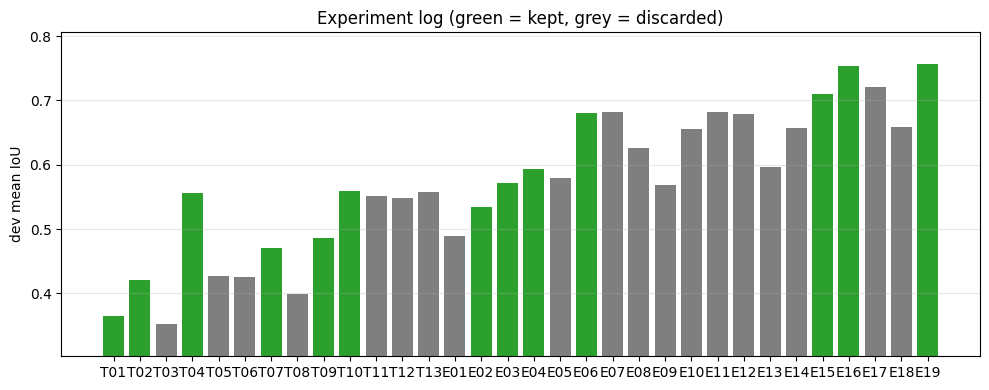

In [25]:
pd.set_option("display.max_colwidth", 90)
display(exp_log[["trial", "what changed", "dev mIoU", "dev mDice", "dev precision", "dev recall",
                 "compared against", "delta", "decision"]])

fig, ax = plt.subplots(figsize=(10, 4))
colors = ["tab:green" if d.startswith("KEPT") else "tab:gray" for d in exp_log["decision"]]
ax.bar(exp_log["trial"], exp_log["dev mIoU"], color=colors)
ax.set_ylabel("dev mean IoU"); ax.set_title("Experiment log (green = kept, grey = discarded)")
ax.set_ylim(max(0, exp_log["dev mIoU"].min() - 0.05), min(1, exp_log["dev mIoU"].max() + 0.05))
ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig(OUT_DIR / "figures" / "experiment_log.png", dpi=130); plt.show()

### Observations

These scores are mean IoU on the 87 development images. The error plots helped explain why some changes worked and others did not.

| Trial | Observation |
|---|---|
| T01–T04 | Plain thresholds are weak: Otsu 0.365 (recall 0.85, precision 0.40) grabs every bright region (cloth, bowl, tray); HSV "white" is a little better (0.420). Border-colour distance is worst (0.352, recall 0.56): the border is not always background, e.g. a hand reaching in from the edge. GrabCut from a centred rectangle is the clear best baseline (0.556), so the "egg is near the centre" prior is useful. |
| T05 | The candidate-and-score pipeline (0.427) is *worse* than GrabCut-rect: the scorer often ranked a bowl rim, tray or tablecloth blob above the egg (precision 0.49, recall 0.67). Kept only as a separate branch to tune, not as the overall best. |
| T06–T09 | Canny regions add nothing (0.426 vs 0.427). Requiring a higher score for extra eggs (T07, thr 0.75) gives +0.044 by removing false extras; a lower threshold hurts (T08). Dropping the whiteness prior (T09) gives +0.015, consistent with shadowed or off-white eggs being penalised. |
| T10–T11 | GrabCut refinement on top of T04 changes almost nothing (+0.0025, only just above the 0.002 keep threshold, so effectively noise). A wider GrabCut band is not better (T11). |
| T12–T13 | Ellipse regularisation and stronger morphology do not help (both within noise of the best, discarded). Phase 1 plateaus at ~0.56; precision (~0.58), not recall (~0.87), is the problem. |
| E01–E05 | Searching for the ellipse outline (E01, 0.489) starts below GrabCut-rect but is more precise and has more headroom. Stricter extra-egg rules (E02, +0.045), a larger minimum egg size (E03, +0.038) and a texture penalty inside the ellipse (E04, +0.021, precision 0.78) each remove a specific failure (false extra eggs, tiny ellipses on clutter, bowl/cloth patterns). Relaxing the brightness prior (E05) hurts. |
| E06–E12 | GrabCut inside a band around each ellipse is the largest single gain (E06, +0.088, recall 0.63 -> 0.72): eggs are only approximately elliptical and the band keeps GrabCut from leaking. GrabCut at 320 px (E07) and union with the ellipse (E11) are within noise of E06 and slower/more complex, so discarded. Colour-similarity rule for extra eggs (E08), tighter GrabCut (E10) and extra morphology (E12) are not better. Forcing a single egg (E09, 0.569) loses ~0.11, so the multi-egg logic is worth keeping. |
| E13–E14 | Changing the contrast cap or percentile weighting lowers mIoU (0.597, 0.657): it makes the score depend on weaker edges and the wrong ellipses win more often. |
| E15 | Penalising dark-inside ellipses more (dark_w 0.3) gives +0.030 (0.710). The reverse change in E05 hurt, so the brightness prior is genuinely useful. |
| E16 | The size prior is the biggest Phase 2b gain (0.754): most near-zero-IoU images were tiny distractor ellipses. |
| E17–E19 | Re-testing a lower cap on top of the size prior still hurts (0.721, 0.658). A stronger size reward (E19, 0.756) is only +0.002 above E16, right at the keep threshold, so treat it as "no real difference". |

**Remaining failure modes** (from the worst-case plots, discussed in Task 3): the search still locks onto a non-egg object with an elliptical outline in cluttered scenes, touching multi-egg groups are under-segmented, and white eggs on a white tray have no boundary contrast.


In [26]:
# The final configuration is the best-scoring dev configuration produced by the experiment loop above
# (best_cfg is set at the end of the experiment-log cell). Nothing is re-typed by hand.
assert best_cfg["method"] == "ellipse"
print("Final dev mIoU from experiment log:", round(best_iou, 4))
print({k: best_cfg[k] for k in ["a_fracs", "w_size", "dark_w", "cap", "w_mean", "w_int", "extra_ratio", "extra_area", "ell_refine"]})


Final dev mIoU from experiment log: 0.756
{'a_fracs': (0.12, 0.15, 0.19, 0.24, 0.3, 0.37, 0.42), 'w_size': 1.5, 'dark_w': 0.3, 'cap': 35.0, 'w_mean': 0.5, 'w_int': 0.2, 'extra_ratio': 0.85, 'extra_area': 0.35, 'ell_refine': 'grabcut'}


## 6. Final evaluation

The settings were chosen using the development images. This cell runs the final method on the evaluation images and saves per-image results and summary metrics. The notebook also shows a bootstrap confidence interval; treat it as approximate because the evaluation set is small.

dev:   0%|          | 0/87 [00:00<?, ?it/s]

eval:   0%|          | 0/22 [00:00<?, ?it/s]

,iou,dice,precision,recall,median IoU,images IoU<0.5,images IoU<0.1,n images,mIoU 95% CI
dev,0.7560,0.8140,0.8353,0.8473,0.8917,14,7,87,"[0.692, 0.816]"
eval,0.7017,0.7837,0.8722,0.8230,0.7857,6,1,22,"[0.578, 0.815]"


check: dev mIoU here = 0.7560 | experiment-log best = 0.7560


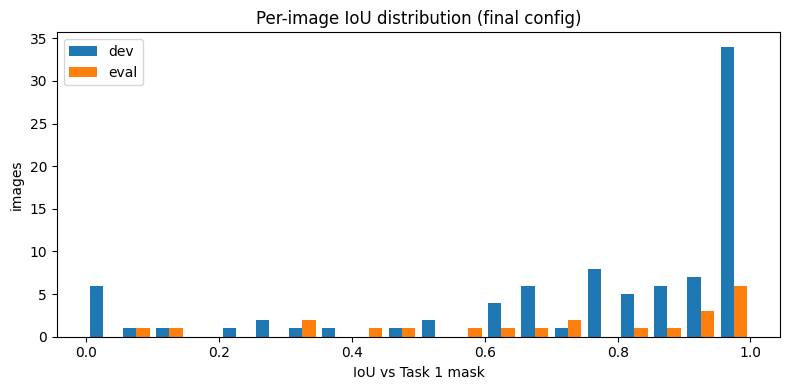

In [27]:
def run_and_save(split_items, cfg, split_name):
    rows = []
    for it in tqdm(split_items, desc=split_name, leave=False):
        pred = segment(it["img"], cfg)
        it[f"pred_{split_name}"] = pred
        cv2.imwrite(str(OUT_DIR / "pred_masks" / split_name / f"{it['stem']}_pred.png"), pred.astype(np.uint8) * 255)
        r = seg_metrics(pred, it["gt"]); r.update(image=it["name"], split=split_name,
                                                  gt_pixels=int(it["gt"].sum()), pred_pixels=int(pred.sum()))
        rows.append(r)
    return pd.DataFrame(rows)

def boot_ci(x, n=5000, seed=SEED):
    x = np.asarray(x, float); rng = np.random.RandomState(seed)
    m = x[rng.randint(0, len(x), (n, len(x)))].mean(1)
    lo, hi = np.percentile(m, [2.5, 97.5]); return f"[{lo:.3f}, {hi:.3f}]"

dev_df = run_and_save(dev_items, best_cfg, "dev")
eval_df = run_and_save(eval_items, best_cfg, "eval")
per_image = pd.concat([dev_df, eval_df], ignore_index=True)
per_image.to_csv(OUT_DIR / "per_image_metrics.csv", index=False)
json.dump(best_cfg, open(OUT_DIR / "final_config.json", "w"), indent=2, default=list)

summary = pd.DataFrame({
    "dev": dev_df[["iou", "dice", "precision", "recall"]].mean(),
    "eval": eval_df[["iou", "dice", "precision", "recall"]].mean(),
}).T
summary["median IoU"] = [dev_df["iou"].median(), eval_df["iou"].median()]
summary["images IoU<0.5"] = [(dev_df["iou"] < 0.5).sum(), (eval_df["iou"] < 0.5).sum()]
summary["images IoU<0.1"] = [(dev_df["iou"] < 0.1).sum(), (eval_df["iou"] < 0.1).sum()]
summary["n images"] = [len(dev_df), len(eval_df)]
summary["mIoU 95% CI"] = [boot_ci(dev_df["iou"]), boot_ci(eval_df["iou"])]
display(summary.round(4))
summary.round(4).to_csv(OUT_DIR / "summary_metrics.csv")
print(f"check: dev mIoU here = {dev_df['iou'].mean():.4f} | experiment-log best = {best_iou:.4f}")

plt.figure(figsize=(8, 4))
plt.hist([dev_df["iou"], eval_df["iou"]], bins=np.linspace(0, 1, 21), label=["dev", "eval"])
plt.xlabel("IoU vs Task 1 mask"); plt.ylabel("images"); plt.legend(); plt.title("Per-image IoU distribution (final config)")
plt.tight_layout(); plt.savefig(OUT_DIR / "figures" / "iou_hist.png", dpi=130); plt.show()


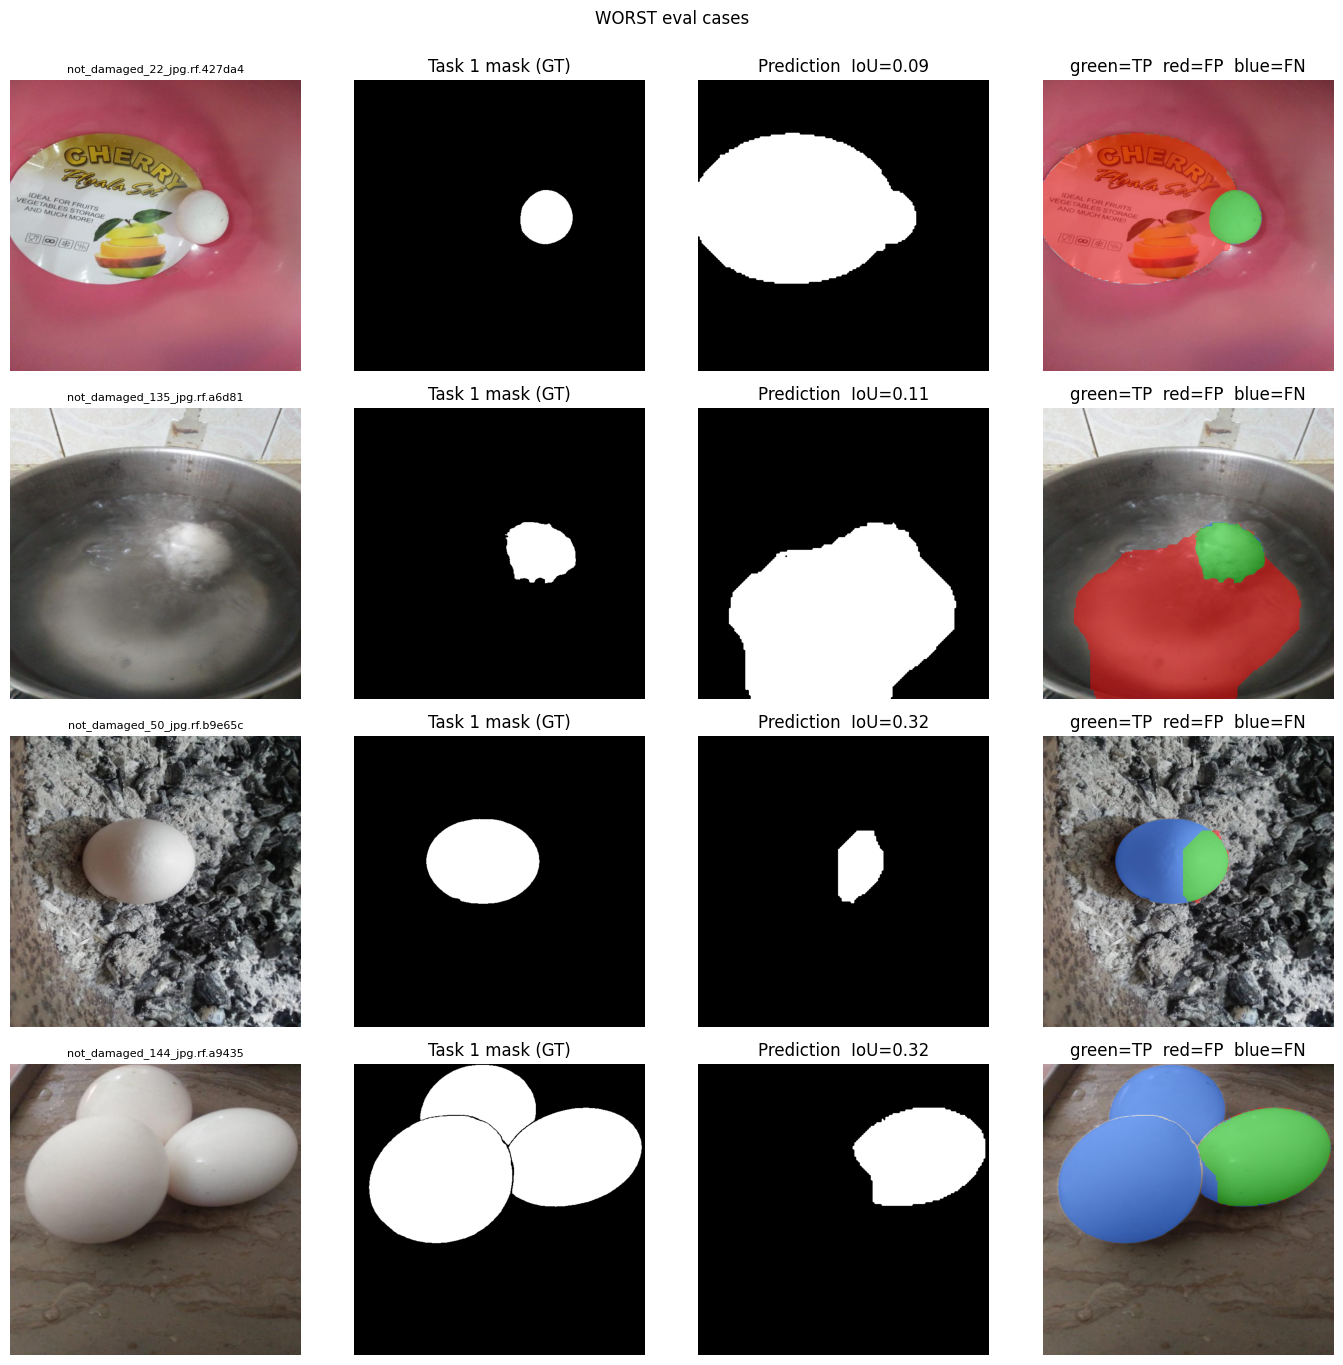

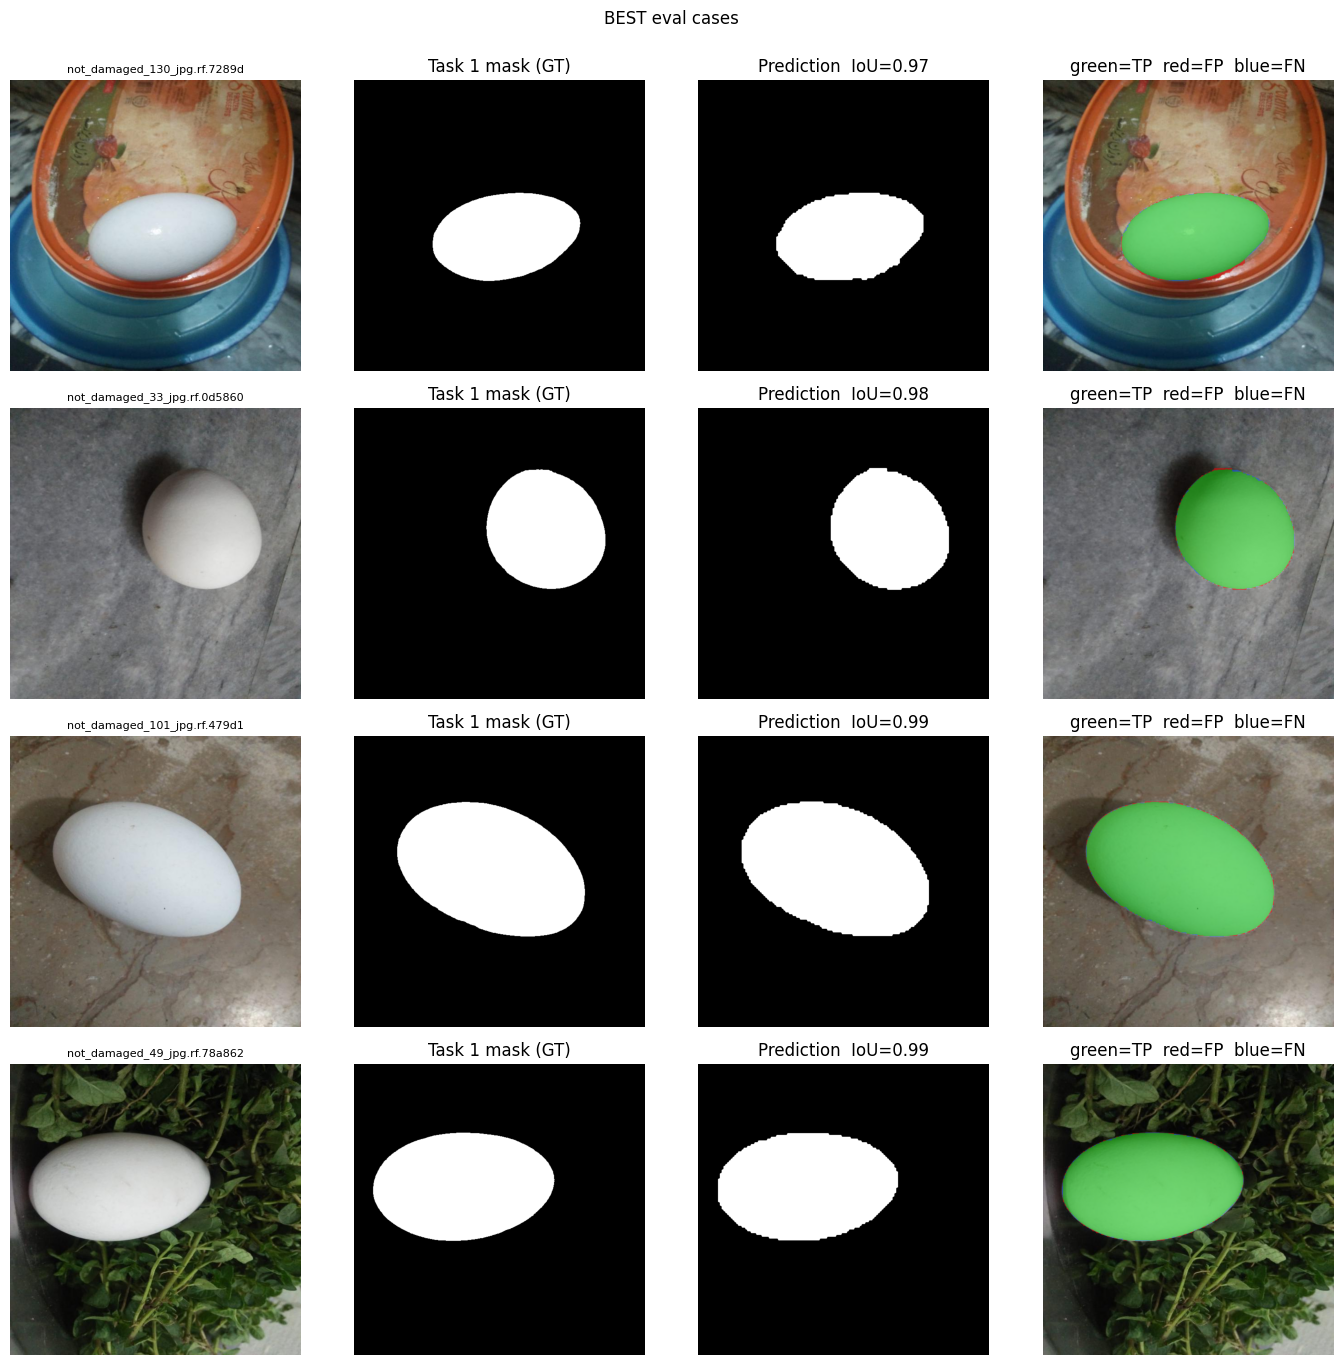

In [28]:
def error_overlay(img, pred, gt):
    ov = img.copy().astype(np.float32)
    tp = pred & gt; fp = pred & ~gt; fn = ~pred & gt
    for m, col in [(tp, (0, 200, 0)), (fp, (255, 0, 0)), (fn, (0, 90, 255))]:
        ov[m] = 0.5 * ov[m] + 0.5 * np.array(col, np.float32)
    return ov.astype(np.uint8)

def show_cases(split_items, key, df, idx_list, title):
    fig, axes = plt.subplots(len(idx_list), 4, figsize=(14, 3.4 * len(idx_list)))
    axes = np.atleast_2d(axes)
    for r, i in enumerate(idx_list):
        it = split_items[i]; pred = it[key]
        axes[r, 0].imshow(it["img"]); axes[r, 0].set_title(it["name"][:28], fontsize=8)
        axes[r, 1].imshow(it["gt"], cmap="gray"); axes[r, 1].set_title("Task 1 mask (GT)")
        axes[r, 2].imshow(pred, cmap="gray"); axes[r, 2].set_title(f"Prediction  IoU={df.iloc[i]['iou']:.2f}")
        axes[r, 3].imshow(error_overlay(it["img"], pred, it["gt"])); axes[r, 3].set_title("green=TP  red=FP  blue=FN")
        for a in axes[r]: a.axis("off")
    fig.suptitle(title, y=1.0); plt.tight_layout(); plt.show()
    return fig

order_eval = np.argsort(eval_df["iou"].values)
n_show = min(4, len(order_eval))
fig = show_cases(eval_items, "pred_eval", eval_df, list(order_eval[:n_show]), "WORST eval cases")
fig.savefig(OUT_DIR / "figures" / "worst_eval.png", dpi=110, bbox_inches="tight")
fig = show_cases(eval_items, "pred_eval", eval_df, list(order_eval[-n_show:]), "BEST eval cases")
fig.savefig(OUT_DIR / "figures" / "best_eval.png", dpi=110, bbox_inches="tight")

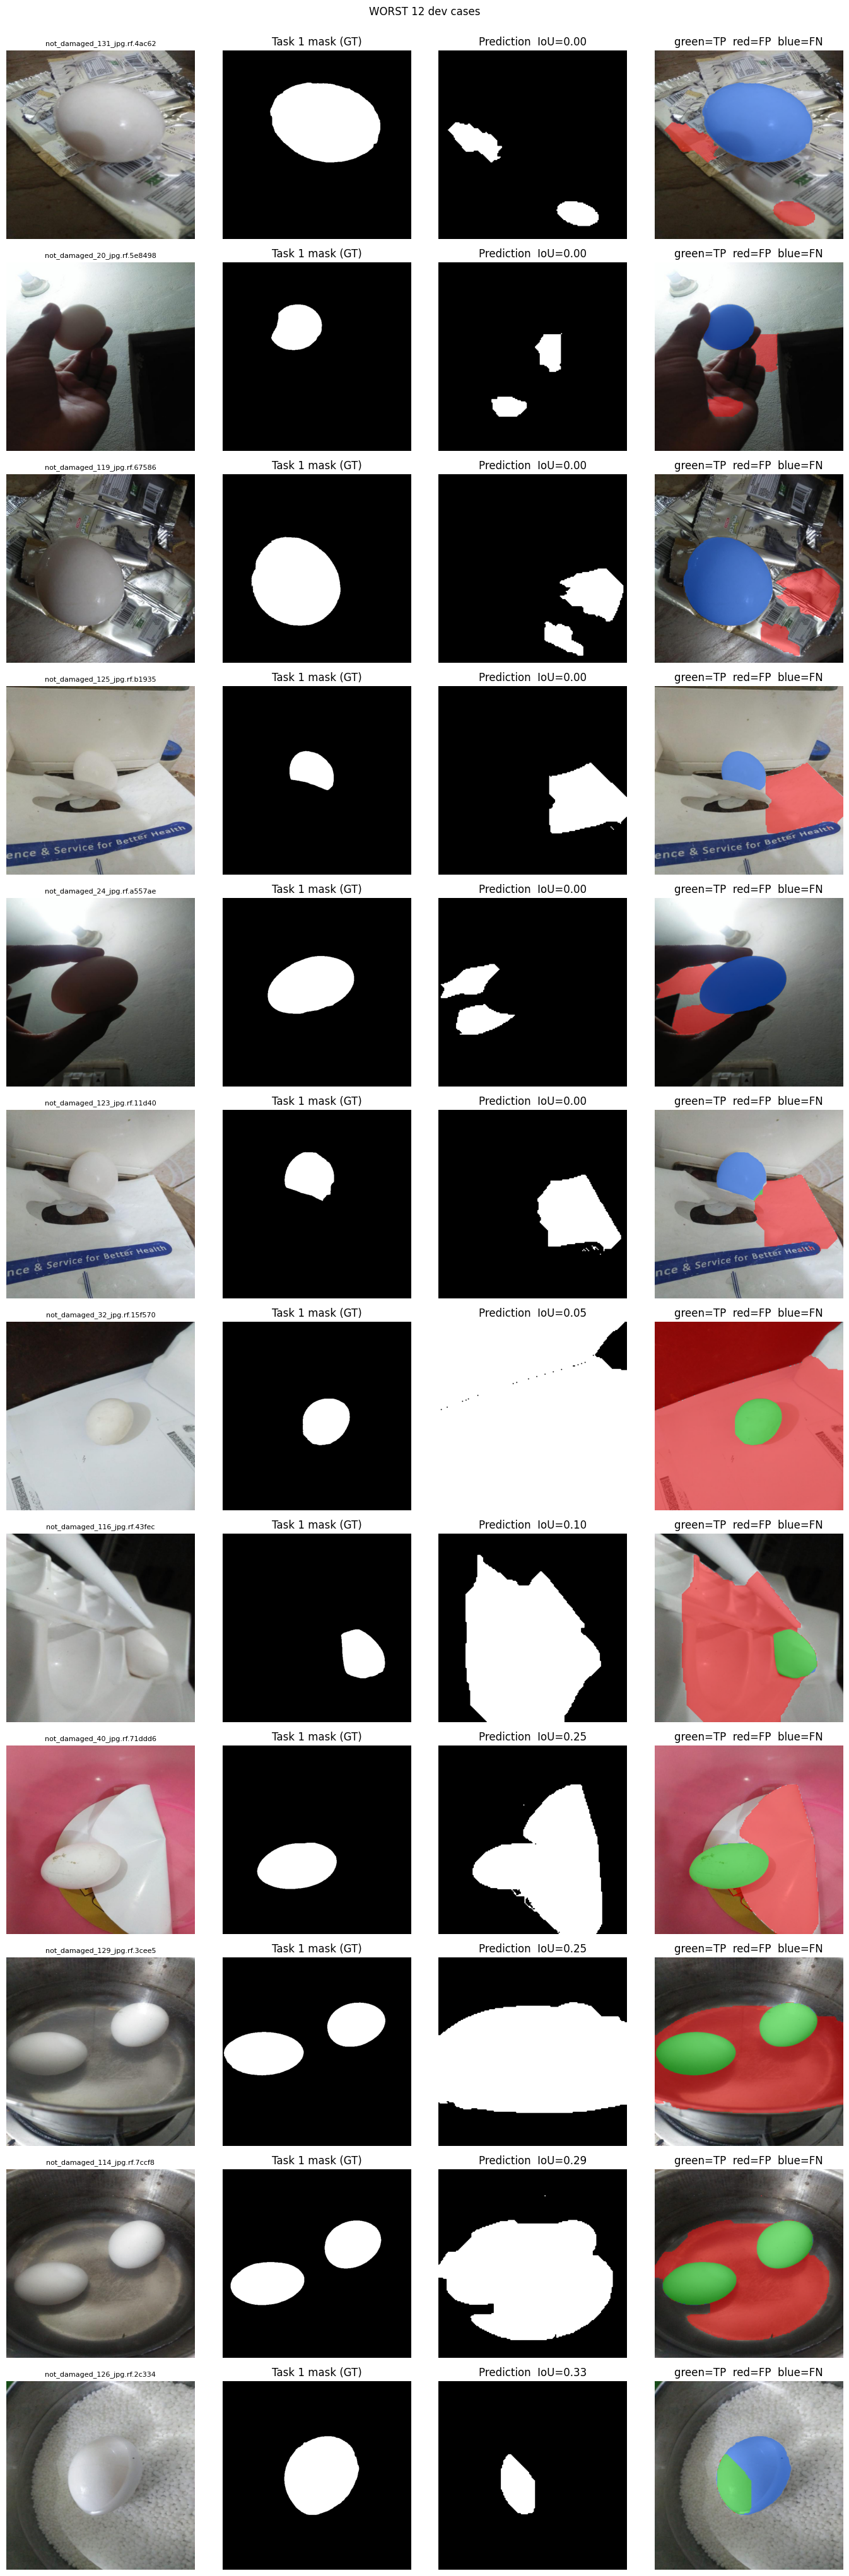

7 dev images with IoU < 0.1


,image,iou,gt_pixels,pred_pixels
0,not_damaged_125_jpg.rf.b19353b1f84dcbef1ec088b850927bb3.jpg,0.000316,14235,45910
22,not_damaged_123_jpg.rf.11d40a86277d3ab3fce1c5c6cbf14db0.jpg,0.004380,19980,48350
27,not_damaged_131_jpg.rf.4ac62f5b18b131bac463f705d0969147.jpg,0.000000,78361,21528
50,not_damaged_20_jpg.rf.5e8498e31e0e596d64f6185f7c56534f.jpg,0.000000,20171,15078
52,not_damaged_24_jpg.rf.a557aeb67c480dc55479509a77b4e160.jpg,0.000526,42865,25672
56,not_damaged_32_jpg.rf.15f5702d8602844d8d866d229e674c89.jpg,0.050204,20009,398553
71,not_damaged_119_jpg.rf.6758625c4b939166ca105d0509fc569e.jpg,0.000000,70120,33832


In [29]:
order_dev = np.argsort(dev_df["iou"].values)
fig = show_cases(dev_items, "pred_dev", dev_df, list(order_dev[:12]), "WORST 12 dev cases")
fig.savefig(OUT_DIR / "figures" / "worst_dev.png", dpi=90, bbox_inches="tight")
bad = dev_df[dev_df["iou"] < 0.1][["image", "iou", "gt_pixels", "pred_pixels"]]
print(len(bad), "dev images with IoU < 0.1")
display(bad)

In [30]:
ZIP_PATH = shutil.make_archive(str(OUT_DIR), "zip", root_dir=str(OUT_DIR.parent), base_dir=OUT_DIR.name)
print("ZIP created:", ZIP_PATH, "| MB:", round(os.path.getsize(ZIP_PATH) / 1024**2, 2))


ZIP created: /kaggle/working/task2_results.zip | MB: 3.27


## A few notes for the written report

- The split is about 4:1 and groups source photos and near-duplicates. Report the counts printed in section 2.
- Task 1 masks are model-generated reference labels, not hand-drawn ground truth. One image with an empty Task 1 mask was excluded.
- The experiment log includes kept and discarded trials. Some improvements are tiny and may be within normal variation.
- The final method searches for egg-shaped outlines, scores their boundary and interior, then uses GrabCut to refine the mask near each outline.
- **Evaluation caveat:** an earlier notebook run looked at evaluation scores before the last E13–E19 development experiments. Those later changes were based on development errors, but the evaluation scores had already been seen, so they are not a completely untouched final check.
- Task 3 uses the saved masks, configuration, and per-image results from this run.
- Disclose the use of AI coding tools in the report, as requested by the assignment.